# 04 - Feature Engineering & Preprocessing (fit on `train_raw`, transform `train`/`val`)

**Objective of this notebook:** translating the decisions drawn from `03_eda.ipynb` (variables to keep, variables needing
log-transform, how to handle outliers/missing...) into **the official data-processing functions**, written in
pure pandas/NumPy (without `sklearn`), placed in `src/preprocessing.py` for reuse across the team.

**3 main functions (in `src/preprocessing.py`):**
1. `clean_raw(df)` — normalises **format/data types** (missing tokens, units, word→number mappings...).
   Does not learn any parameters from data, can be used on train/val/test.

2. `fit_preprocessing(train_df)` — **ONLY call on `train_raw` after `clean_raw()`**. Learns (fits)
   all processing parameters (imputation values, IQR outlier bounds, mean/std for scaling...) and returns a `params` dict.
   
3. `transform(raw_df, params)` — reuses `clean_raw()` internally, then applies fitted `params` to produce
   `X` (features) and `y` (target `mpg`). Can be used for **train/val/test**.

**Mandatory rules:**
- `fit_preprocessing()` **must ONLY run on `train_raw`** — no value (median, mean, std, outlier
  thresholds...) may be computed based on `val_raw`/`test_raw`, to avoid **data leakage**.

- `val_raw` may only be **`transform()`**-ed using parameters fitted from train, it must not be used to refit.

- `test_raw` **must not be touched in this notebook** — You can self-`transform()` using
  `preprocessing_params.pkl` when needed, at the train model step.

> 🔧 **Update:** `clean_raw()` in `src/preprocessing.py` has just had a
> condition added to filter negative `weight` → `NaN`, in line with the finding in `03_eda.ipynb` (section 1.1) — see the
> specific confirmation in section 1 below.


## 0. Environment setup & visualisation style

Besides `pandas`/`numpy` (data processing), this notebook also uses
`matplotlib`/`seaborn` **only for visualising** the fitted parameters — it does not affect the data
processing logic.


In [1]:
# Import libraries - data processing uses ONLY pure pandas/numpy (NO sklearn);
# matplotlib/seaborn are ONLY for presenting/visualising the fitted parameters.
import sys
import os
import pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': '#4a4a4a',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlepad': 10,
    'axes.labelsize': 10.5, 'grid.alpha': 0.35, 'font.family': 'DejaVu Sans',
})
COLOR_MAIN, COLOR_HIGHLIGHT, COLOR_SECONDARY = '#2A6F97', '#A63446', '#588157'


def find_project_root(start=None, required_dirs=('src', 'data_processed'), max_levels=6):
    current = os.path.abspath(start or os.getcwd())
    for _ in range(max_levels):
        conditions_met = all(
            os.path.isdir(os.path.join(current, name)) for name in required_dirs
        )
        if conditions_met:
            return current
        parent = os.path.dirname(current)
        if parent == current:   # reached the filesystem root, stop
            break
        current = parent
    return None


print(f'Current kernel working directory (cwd): {os.getcwd()}')

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise RuntimeError(
        'Could not find the project root directory (must contain both "src/" and "data_processed/"). '
        'Check that: (1) you have run 02_split.ipynb to create data_processed/train_raw.csv..., '
        '(2) the directory structure matches the expected layout (src/, data_processed/, notebooks/ sitting alongside each other).'
    )

print(f'Found project root directory: {PROJECT_ROOT}')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.preprocessing import (
    clean_raw,
    fit_preprocessing,
    transform,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    LOG_TRANSFORM_COLUMNS,
    OUTLIER_COLUMNS,
)

OUT_DIR = os.path.join(PROJECT_ROOT, 'data_processed')
TRAIN_PATH = os.path.join(OUT_DIR, 'train_raw.csv')
# VAL_PATH: val will be split from train during evaluation if needed
TEST_PATH = os.path.join(OUT_DIR, 'test_raw.csv')   # ONLY used for ILLUSTRATION at the end of the notebook, not processed officially here
PARAMS_PATH = os.path.join(OUT_DIR, 'preprocessing_params.pkl')
print('Finished importing src/preprocessing.py and defining data paths.')


Current kernel working directory (cwd): d:\ĐH\Năm 2\Học kỳ hè\Machine Learning\Source code compilation\Polynomial Regression\notebooks
Found project root directory: d:\ĐH\Năm 2\Học kỳ hè\Machine Learning\Source code compilation\Polynomial Regression
Finished importing src/preprocessing.py and defining data paths.


## 1. Load `train_raw` and apply `clean_raw()`

Read the **raw** data (keep it as strings, don't let pandas auto-infer types), then call `clean_raw()` from
`src/preprocessing.py` to standardise the data format/types (this is **not yet** the parameter-fitting step).


In [2]:
train_raw = pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False, na_values=[])
print(f'Shape of train_raw (before clean_raw): {train_raw.shape}')

train_clean = clean_raw(train_raw)
print(f'Shape of train_clean (after clean_raw): {train_clean.shape}')
print('(the row count may drop slightly due to removal of extra duplicate rows / fully-NaN rows left after format standardisation)')

# Confirm the "negative weight" fix (found in 03_eda.ipynb section 1.1) is working correctly in clean_raw()
remaining_negative_weight = int((train_clean['weight'] < 0).sum())
print(f"\nRemaining rows with weight < 0 after clean_raw(): {remaining_negative_weight}  (expected: 0)")
assert remaining_negative_weight == 0, 'ERROR: clean_raw() did not filter out all negative weight values!'
print('=> Passed: negative weight has been converted to NaN as noted in 03_eda.ipynb.')

train_clean.head()


Shape of train_raw (before clean_raw): (322, 9)
Shape of train_clean (after clean_raw): (320, 9)
(the row count may drop slightly due to removal of extra duplicate rows / fully-NaN rows left after format standardisation)

Remaining rows with weight < 0 after clean_raw(): 0  (expected: 0)
=> Passed: negative weight has been converted to NaN as noted in 03_eda.ipynb.


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,31.5,4.0,98.0,NaN,2045.0,18.5,1977.0,3.0,honda accord cvcc
1,24.5,4.0,151.0,88.0,2740.0,16.0,1977.0,1.0,pontiac sunbird coupe
2,12.0,8.0,350.0,180.0,4499.0,12.5,1973.0,1.0,oldsmobile vista cruiser
3,24.0,4.0,113.0,95.0,2372.0,15.0,1970.0,3.0,TOYOTA CORONA MARK II
4,24.0,6.0,200.0,81.0,3012.0,17.6,1976.0,1.0,ford maverick


### 1.1 Missing-value picture after `clean_raw()`

Compared to the original raw data, missing tokens (`'?'`, `'unknown'`, empty cell...) have been mapped to real
`NaN`; at the same time, physically unrealistic values (`horsepower` negative/too large, `weight` negative, `model year` outside
1960–2030, `mpg` > 200) have also been converted to `NaN` for uniform handling at the impute step.


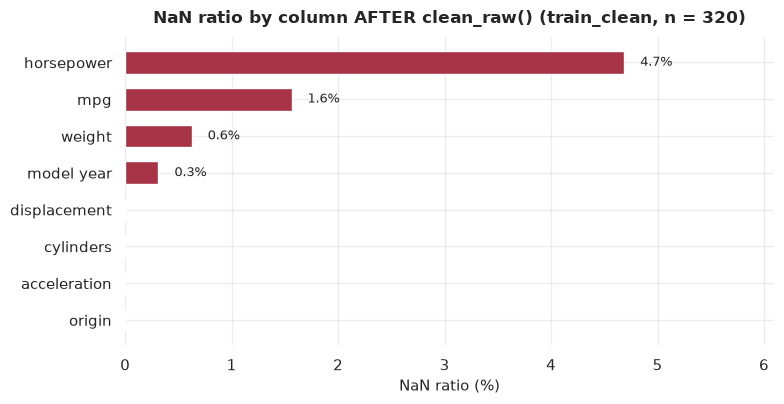

Number of NaNs per column after clean_raw (train_clean):


mpg              5
cylinders        0
displacement     0
horsepower      15
weight           2
acceleration     0
model year       1
origin           0
car name         0
dtype: int64

In [3]:
missing_ratio = (train_clean.drop(columns=['car name']).isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(missing_ratio.index[::-1], missing_ratio.values[::-1],
                color=[COLOR_HIGHLIGHT if v > 0 else '#c9c9c9' for v in missing_ratio.values[::-1]],
                edgecolor='white', height=0.62)
for b, v in zip(bars, missing_ratio.values[::-1]):
    if v > 0:
        ax.text(v + 0.15, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', fontsize=9.5)
ax.set_xlabel('NaN ratio (%)')
ax.set_title(f'NaN ratio by column AFTER clean_raw() (train_clean, n = {len(train_clean)})')
ax.set_xlim(0, max(missing_ratio.max() * 1.3, 5))
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print('Number of NaNs per column after clean_raw (train_clean):')
train_clean.isna().sum()


## 2. Feature engineering decisions — from `03_eda.ipynb` conclusions

| Decision | Content | Source |
|---|---|---|
| **Input variables (features)** | `cylinders, displacement, horsepower, weight, acceleration, model year, origin` | EDA section 7: keep all variables with physical meaning/correlation with `mpg`; `origin` is a categorical code (1/2/3) still kept as a numeric variable, using degree 1 (degree=1) when fed into Polynomial Regression |
| **Target variable** | `mpg` | — |
| **Log-transform** | `horsepower` | EDA section 2: `\|skew\| > 1` is the threshold for strong skew. Re-checking with real numbers from `train_raw` (see cell below) shows only `horsepower` clearly exceeds this threshold |
| **Outlier (IQR of train)** | `horsepower`, `weight`, `mpg` | Per project requirements + consistent with the columns already found to have unrealistic outliers in `01_data_overview.ipynb` (horsepower negative/too large, mpg = 9999...) |
| **Impute missing** | Median of `train` for each numeric column | Median is more robust than mean in the presence of outliers/skewed distributions |
| **Scaling** | `(x - mean) / std`, mean/std computed on `train` (after impute + outlier clipping + log-transform) | Implemented from scratch with NumPy/pandas, without `StandardScaler` |
| **Negative weight → NaN** | New addition | EDA section 1.1: negative `weight` is physically unrealistic, handled consistently with the approach already used for `horsepower`/`model year` |

Specific list declared in `src/preprocessing.py`:


In [4]:
print('FEATURE_COLUMNS      :', FEATURE_COLUMNS)
print('TARGET_COLUMN         :', TARGET_COLUMN)
print('LOG_TRANSFORM_COLUMNS :', LOG_TRANSFORM_COLUMNS)
print('OUTLIER_COLUMNS       :', OUTLIER_COLUMNS)


FEATURE_COLUMNS      : ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin']
TARGET_COLUMN         : mpg
LOG_TRANSFORM_COLUMNS : ['horsepower']
OUTLIER_COLUMNS       : ['horsepower', 'weight', 'mpg']


### Re-validating the log-transform choice using real `train_clean` numbers

In `03_eda.ipynb`, skewness was illustrated on a temporary snapshot (`df_eda`). Here we recompute it
using the exact same formula (pandas' `Series.skew()`, no `scipy`) on the **entire real `train_clean`**,
both **before** and **after** clipping outliers by IQR, to confirm which columns truly need log-transform.


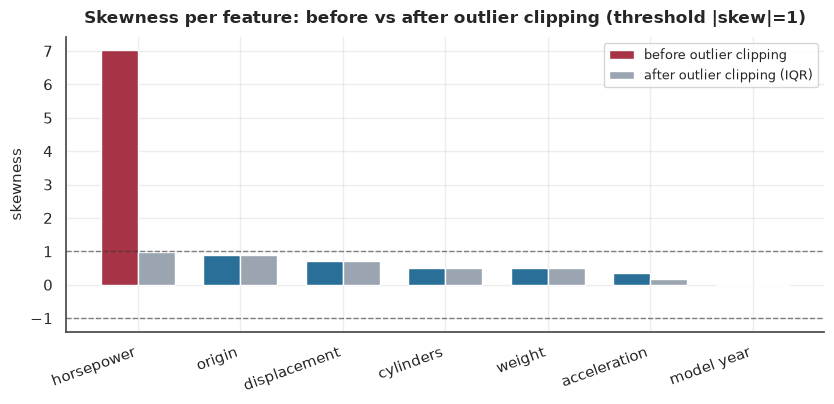

,column,skew_before_outlier_clip,skew_after_outlier_clip,strongly_skewed_before (|skew|>1)
2,horsepower,7.020,0.984,True
6,origin,0.905,0.905,False
1,displacement,0.712,0.712,False
0,cylinders,0.506,0.506,False
3,weight,0.496,0.496,False
4,acceleration,0.346,0.185,False
5,model year,0.003,0.003,False


In [5]:
def _iqr_bounds(s):
    s2 = s.dropna()
    q1, q3 = s2.quantile(0.25), s2.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

skew_table = []
for col in FEATURE_COLUMNS:
    s = train_clean[col]
    skew_before = s.skew()
    lower, upper = _iqr_bounds(s)
    skew_after_clip = s.clip(lower=lower, upper=upper).skew()
    skew_table.append({
        'column': col, 'skew_before_outlier_clip': round(skew_before, 3),
        'skew_after_outlier_clip': round(skew_after_clip, 3),
        'strongly_skewed_before (|skew|>1)': abs(skew_before) > 1,
    })
skew_df = pd.DataFrame(skew_table).sort_values('skew_before_outlier_clip', key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(skew_df))
w = 0.36
color_before = [COLOR_HIGHLIGHT if v else COLOR_MAIN for v in skew_df['strongly_skewed_before (|skew|>1)']]
ax.bar(x - w/2, skew_df['skew_before_outlier_clip'], width=w, color=color_before, label='before outlier clipping', edgecolor='white')
ax.bar(x + w/2, skew_df['skew_after_outlier_clip'], width=w, color='#9AA5B1', label='after outlier clipping (IQR)', edgecolor='white')
ax.axhline(1, color='#333333', linestyle='--', linewidth=1, alpha=0.6)
ax.axhline(-1, color='#333333', linestyle='--', linewidth=1, alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(skew_df['column'], rotation=20, ha='right')
ax.set_ylabel('skewness')
ax.set_title('Skewness per feature: before vs after outlier clipping (threshold |skew|=1)')
ax.legend(fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

skew_df


**Observation:** 
Only `horsepower` has `|skew| > 1` clearly (skewed by a few unrealistic outlier values,
e.g. `850` hp appearing repeatedly), so **only log-transform
`horsepower`**. `weight` and `displacement` have `|skew| < 1` on this real data so log-transform is not needed,
avoiding unnecessary transformation that reduces regression coefficient interpretability.


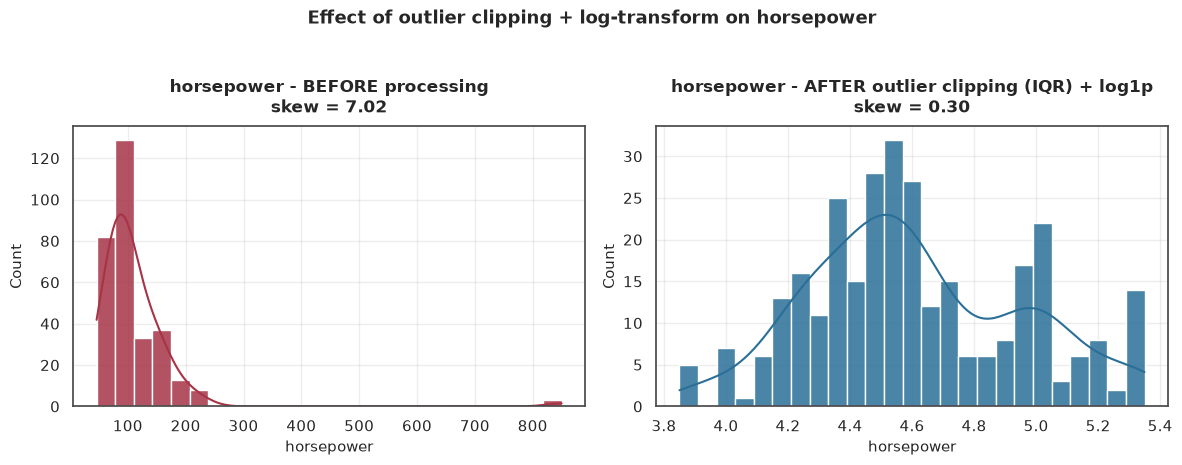

In [6]:
# Visual illustration of the effect of log1p on horsepower: distribution before vs after
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
hp = train_clean['horsepower'].dropna()
hp_clip = hp.clip(*_iqr_bounds(train_clean['horsepower']))
hp_log = np.log1p(hp_clip)

sns.histplot(hp, bins=25, color=COLOR_HIGHLIGHT, ax=axes[0], kde=True, edgecolor='white', alpha=0.85)
axes[0].set_title(f'horsepower - BEFORE processing\nskew = {hp.skew():.2f}')

sns.histplot(hp_log, bins=25, color=COLOR_MAIN, ax=axes[1], kde=True, edgecolor='white', alpha=0.85)
axes[1].set_title(f'horsepower - AFTER outlier clipping (IQR) + log1p\nskew = {hp_log.skew():.2f}')

fig.suptitle('Effect of outlier clipping + log-transform on horsepower', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 3. `fit_preprocessing()` — run ONLY on `train_clean`

Learns all parameters (impute, IQR outlier bounds, mean/std for scaling) **exclusively from `train_clean`**.
**Never call this function on `val_raw`/`test_raw`** — doing so would cause **data leakage**
(processing parameters would "see" validation/test information beforehand).


In [7]:
params = fit_preprocessing(train_clean)
print('Keys in params:', list(params.keys()))


Keys in params: ['features', 'target', 'log_transform_cols', 'impute_values', 'outlier_bounds', 'scale_mean', 'scale_std']


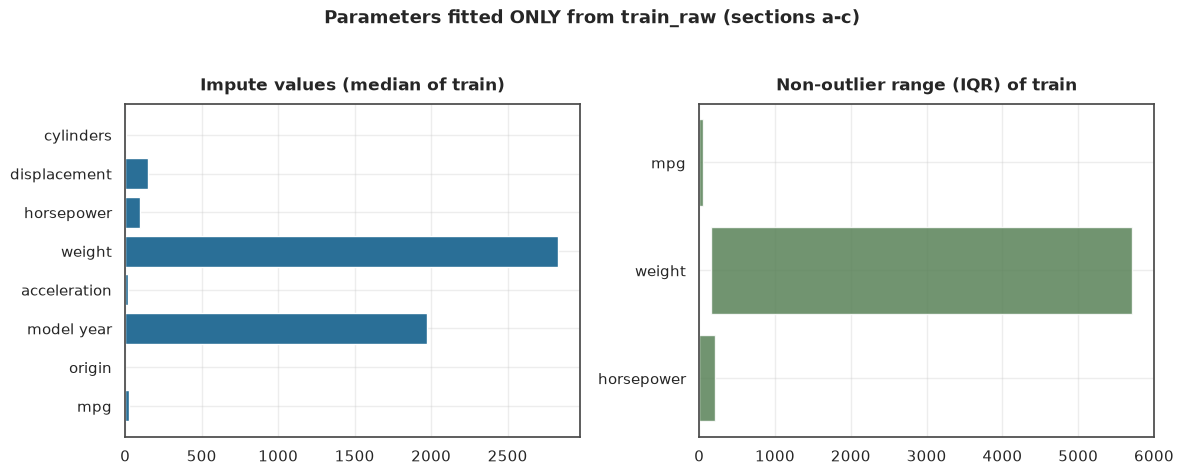

--- Impute values (median of train) ---


,impute_value
cylinders,4.0
displacement,151.0
horsepower,95.0
weight,2831.5
acceleration,15.5
model year,1976.0
origin,1.0
mpg,22.3



--- Outlier clipping thresholds (IQR of train) ---


,lower,upper
horsepower,1.1250,206.1250
weight,157.3750,5714.3750
mpg,-0.0625,46.4375



--- Mean / Std for scaling (computed on train, AFTER impute + outlier clipping + log-transform) ---


,mean,std
cylinders,5.478125,1.715597
displacement,194.689063,104.172143
horsepower,4.606824,0.335107
weight,2988.237500,841.417326
acceleration,15.555937,2.806326
model year,1976.053125,3.628058
origin,1.581250,0.809876


In [8]:
impute_table = pd.Series(params['impute_values'], name='impute_value').to_frame()
outlier_table = pd.DataFrame(params['outlier_bounds'], index=['lower', 'upper']).T
scale_table = pd.DataFrame({'mean': params['scale_mean'], 'std': params['scale_std']})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

axes[0].barh(impute_table.index[::-1], impute_table['impute_value'][::-1], color=COLOR_MAIN, edgecolor='white')
axes[0].set_title('Impute values (median of train)')

y_pos = np.arange(len(outlier_table))
axes[1].barh(y_pos, outlier_table['upper'] - outlier_table['lower'], left=outlier_table['lower'],
             color=COLOR_SECONDARY, edgecolor='white', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(outlier_table.index)
axes[1].set_title('Non-outlier range (IQR) of train')

fig.suptitle('Parameters fitted ONLY from train_raw (sections a-c)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print('--- Impute values (median of train) ---')
display(impute_table)
print('\n--- Outlier clipping thresholds (IQR of train) ---')
display(outlier_table)
print('\n--- Mean / Std for scaling (computed on train, AFTER impute + outlier clipping + log-transform) ---')
display(scale_table)


## 4. Save `params` to `data_processed/preprocessing_params.pkl`

Uses Python's standard `pickle` module (**not sklearn's `joblib`**), so params can be reloaded and
`transform()` called independently without re-running this notebook.


In [9]:
os.makedirs(OUT_DIR, exist_ok=True)

with open(PARAMS_PATH, 'wb') as f:
    pickle.dump(params, f)

print(f'Saved params to: {PARAMS_PATH}')


Saved params to: d:\ĐH\Năm 2\Học kỳ hè\Machine Learning\Source code compilation\Polynomial Regression\data_processed\preprocessing_params.pkl


## 5. `transform()` for `train_raw`

Call `transform()` on `train_raw` using `params` fitted in step 3.
Note: `test_raw.csv` remains raw and untouched. If a validation set is needed for hyperparameter tuning,
it will be split directly from `train` at the evaluation stage.


In [10]:
X_train, y_train = transform(train_raw, params)

print(f'X_train: {X_train.shape}   y_train: {y_train.shape}')


X_train: (315, 7)   y_train: (315,)


Remaining NaN count in X_train: 0
Remaining NaN count in y_train: 0


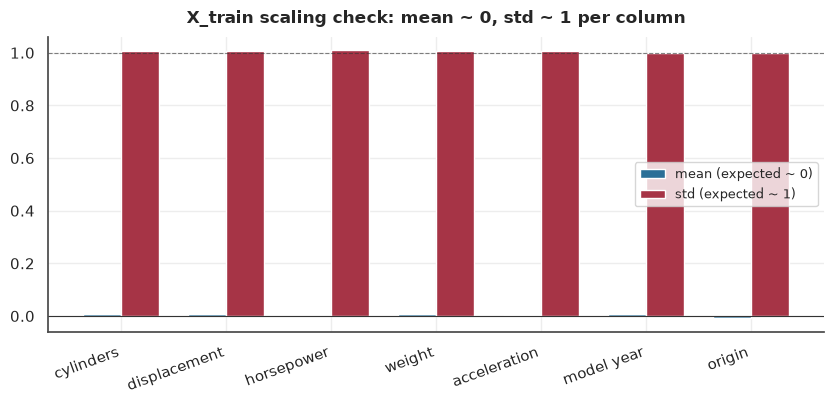


X_train scaling check (expected mean ~ 0, std ~ 1):


,mean,std
cylinders,0.006,1.006
displacement,0.006,1.006
horsepower,0.001,1.009
weight,0.006,1.006
acceleration,0.004,1.008
model year,0.007,0.998
origin,-0.008,0.998


,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,-0.861581,-0.928166,-0.126752,-1.121010,1.049081,0.260987,1.751812
1,-0.861581,-0.419393,-0.352685,-0.295023,0.158236,0.260987,-0.717703
2,1.469970,1.490907,1.765627,1.795497,-1.088946,-0.841532,-0.717703
3,-0.861581,-0.784174,-0.126752,-0.732380,-0.198102,-1.668420,1.751812
4,0.304194,0.050982,-0.597136,0.028241,0.728377,-0.014643,-0.717703


In [11]:
# Check there is no remaining NaN in X/y after transform
print('Remaining NaN count in X_train:', int(X_train.isna().sum().sum()))
print('Remaining NaN count in y_train:', int(y_train.isna().sum()))

mean_std = X_train.describe().T[['mean', 'std']]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(mean_std))
w = 0.36
ax.bar(x - w/2, mean_std['mean'], width=w, color=COLOR_MAIN, edgecolor='white', label='mean (expected ~ 0)')
ax.bar(x + w/2, mean_std['std'], width=w, color=COLOR_HIGHLIGHT, edgecolor='white', label='std (expected ~ 1)')
ax.axhline(0, color='#333333', linewidth=0.8)
ax.axhline(1, color='#333333', linewidth=0.8, linestyle='--', alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(mean_std.index, rotation=20, ha='right')
ax.set_title('X_train scaling check: mean ~ 0, std ~ 1 per column')
ax.legend(fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

print('\nX_train scaling check (expected mean ~ 0, std ~ 1):')
display(mean_std.round(3))

X_train.head()


## 6. Save `X_train.csv` and `y_train.csv`

**`test_raw.csv` is not touched in this notebook** — per the project constraints, test always stays raw.
Validation set will be split from train during model evaluation if needed.


In [12]:
X_train_path = os.path.join(OUT_DIR, 'X_train.csv')
y_train_path = os.path.join(OUT_DIR, 'y_train.csv')

X_train.to_csv(X_train_path, index=False)
y_train.to_csv(y_train_path, index=False)

print('Saved:')
print(f'  {X_train_path}  -> shape {X_train.shape}')
print(f'  {y_train_path}  -> shape {y_train.shape}')


Saved:
  d:\ĐH\Năm 2\Học kỳ hè\Machine Learning\Source code compilation\Polynomial Regression\data_processed\X_train.csv  -> shape (315, 7)
  d:\ĐH\Năm 2\Học kỳ hè\Machine Learning\Source code compilation\Polynomial Regression\data_processed\y_train.csv  -> shape (315,)


## Conclusion

- `src/preprocessing.py` contains all 3 functions: `clean_raw()`, `fit_preprocessing()`, `transform()`; `clean_raw()` has just had handling
  for negative `weight` added (found from `03_eda.ipynb`), reconfirmed in section 1.

- `fit_preprocessing()` runs **exactly once on `train_clean`**; all learned parameters have been
  saved to `data_processed/preprocessing_params.pkl` (using standard `pickle`).

- `X_train.csv` and `y_train.csv` were created by calling `transform()` with
  parameters fitted from train — validation set will be split from train at evaluation.

- The visual sanity check (section 5) confirms: no NaN remains, and standardisation (mean ~ 0, std ~ 1) is
  as expected on `X_train`.

- `test_raw.csv` **has not been touched** — `transform()` can be called with `preprocessing_params.pkl`
  at any time in `train_model/`, independently of this notebook.
